# 06 — Product analytics
Rank products by revenue and units sold using order-item and product tables.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ecommerce_analytics.config import ConfigManager
from ecommerce_analytics.db_engine import DatabaseEngine
from ecommerce_analytics.product_analytics import ProductAnalytics

# Initialize DB connection and product engine
db = DatabaseEngine()
product_engine = ProductAnalytics(db_engine=db)

DATABASE_URL not found in .env. Falling back to local SQLite: C:\Users\nazmu\Documents\data_analysis\ecommerce-analytics\data\processed\ecommerce_analytics.db


In [2]:
# Run Pareto 80/20 Analysis
pareto_df = product_engine.get_pareto_category_analysis()

# Display Pareto Summary Table
display(pareto_df[["category_name", "category_revenue", "revenue_share_pct", "cumulative_share_pct", "pareto_class"]].head(15))

# Plot Pareto Cumulative Curve
fig, ax1 = plt.subplots(figsize=(12, 6))

top_20_cats = pareto_df.head(20)

ax1.bar(top_20_cats["category_name"], top_20_cats["category_revenue"] / 1e3, color="#2b5c8f", alpha=0.85)
ax1.set_ylabel("Category Revenue (k BRL)", color="#2b5c8f", fontweight="bold")
plt.xticks(rotation=90)

ax2 = ax1.twinx()
ax2.plot(top_20_cats["category_name"], top_20_cats["cumulative_share_pct"], color="#d9534f", marker="o", linewidth=2)
ax2.axhline(80, color="gray", linestyle="--", label="80% Revenue Cutoff")
ax2.set_ylabel("Cumulative Revenue Share (%)", color="#d9534f", fontweight="bold")

plt.title("Pareto 80/20 Analysis: Product Category Revenue Concentration", pad=15)
plt.tight_layout()
plt.show()

,category_name,category_revenue,revenue_share_pct,cumulative_share_pct,pareto_class
0,health_beauty,1233131.72,9.326717,9.326717,Core Category (Top 80% Revenue)
1,watches_gifts,1166176.98,8.820309,18.147026,Core Category (Top 80% Revenue)
2,bed_bath_table,1023434.76,7.740687,25.887713,Core Category (Top 80% Revenue)
3,sports_leisure,954852.55,7.221969,33.109682,Core Category (Top 80% Revenue)
4,computers_accessories,888724.61,6.721815,39.831497,Core Category (Top 80% Revenue)
5,furniture_decor,711927.69,5.384622,45.216119,Core Category (Top 80% Revenue)
6,housewares,615628.69,4.656270,49.872389,Core Category (Top 80% Revenue)
7,cool_stuff,610204.10,4.615242,54.487631,Core Category (Top 80% Revenue)
8,auto,578966.65,4.378979,58.866610,Core Category (Top 80% Revenue)
9,toys,471286.48,3.564547,62.431157,Core Category (Top 80% Revenue)


<Figure size 1200x600 with 2 Axes>

,category_name,items_sold,avg_price_brl,avg_freight_brl,avg_weight_g,freight_to_price_ratio_pct
0,home_appliances_2,231,467.333117,44.392078,8926.142857,9.50
1,kitchen_dining_laundry_garden_furniture,274,166.175109,42.120401,8938.142336,25.35
2,office_furniture,1668,160.763975,40.202068,11340.064149,25.01
3,furniture_living_room,495,136.062020,35.746202,8101.210101,26.27
4,industry_commerce_and_business,265,145.278528,28.605774,6601.732075,19.69
5,luggage_accessories,1077,128.785172,27.926175,5803.448468,21.68
6,musical_instruments,651,283.127097,27.452197,3134.539171,9.70
7,agro_industry_and_commerce,206,342.553883,27.365049,3683.126214,7.99
8,construction_tools_lights,301,132.747508,24.884186,3386.926910,18.75
9,small_appliances,658,277.741824,23.334878,2929.352584,8.40


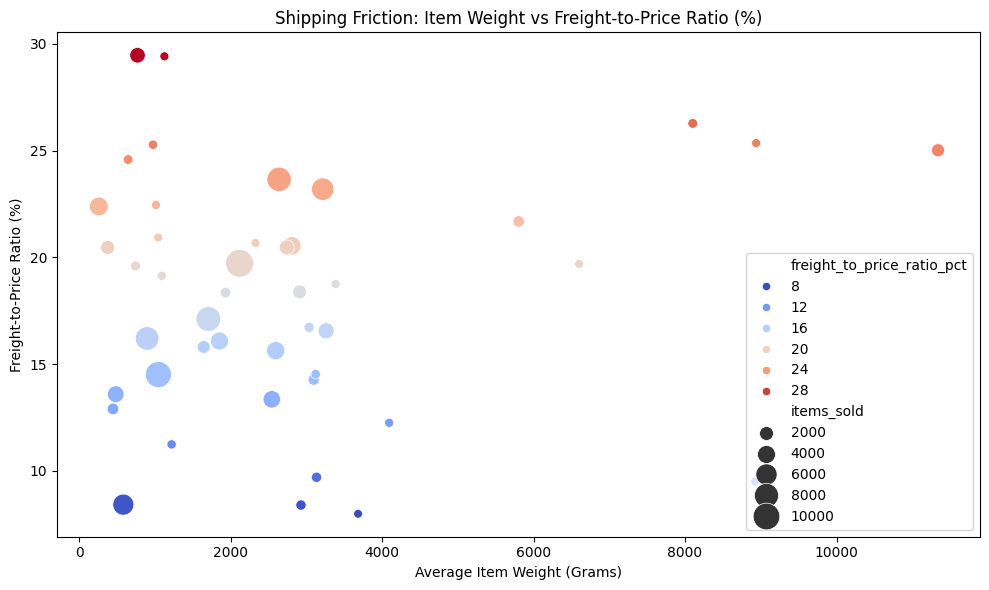

In [3]:
# Fetch freight friction metrics
friction_df = product_engine.get_freight_friction_analysis()

# Render top high-freight categories
display(friction_df.head(10))

# Scatter Plot: Item Weight vs Freight-to-Price Ratio
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=friction_df,
    x="avg_weight_g",
    y="freight_to_price_ratio_pct",
    size="items_sold",
    hue="freight_to_price_ratio_pct",
    palette="coolwarm",
    sizes=(40, 400)
)
plt.title("Shipping Friction: Item Weight vs Freight-to-Price Ratio (%)")
plt.xlabel("Average Item Weight (Grams)")
plt.ylabel("Freight-to-Price Ratio (%)")
plt.tight_layout()
plt.show()